# Tucson Case Study Pattern Identification

This notebook identifies citywide and context-specific response patterns in SHAP dependence values. The case-study specification uses an XGBoost model, four intersection context groups, and ten selected determinants. Candidate forms are compared using fit criteria and bootstrap summaries, with conditional tests for the fitted parameters.

The analysis uses the prepared dataset in `Input_Data/final_pedestrian_data.csv`. Run cells in order from the repository directory.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.cluster import KMeans
from sklearn.metrics import r2_score
from xgboost import XGBRegressor

PROJECT_DIR = Path.cwd()
FIGURE_DIR = PROJECT_DIR / "Images"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = PROJECT_DIR / 'Input_Data' / 'final_pedestrian_data.csv'
TARGET = 'HourlyPedCount'

# XGBoost specification for the case-study pattern analysis.

MODEL_PARAMS = {
    'n_estimators': 400, 'max_depth': 3, 'learning_rate': 0.20,
    'subsample': 1.0, 'colsample_bytree': 0.60, 'min_child_weight': 3,
    'reg_alpha': 0.001, 'reg_lambda': 10.0,
    'objective': 'count:poisson', 'tree_method': 'hist', 'random_state': 42,
}

# Load numeric predictors in their analysis units.
METADATA_COLUMNS = ['DeviceID', 'DateHour', 'Latitude', 'Longitude', TARGET]
raw_df = pd.read_csv(DATA_PATH, parse_dates=['DateHour'], float_precision='round_trip')
y = raw_df[TARGET].astype(float)
x_df = raw_df.drop(columns=METADATA_COLUMNS).astype(float)
x_df = x_df.replace([np.inf, -np.inf], np.nan).fillna(x_df.mean())
x_np = x_df.to_numpy(dtype=float)

crime_columns_retained = [column for column in x_df.columns if 'crime' in column.lower() or 'incident' in column.lower()]
assert not crime_columns_retained, f'Unexpected crime/incident features retained: {crime_columns_retained}'
print(f'Rows: {len(x_df):,}; predictors: {x_df.shape[1]}; crime/incident features retained: none.')

Rows: 1,708; predictors: 171; crime/incident features retained: none.


## Citywide Feature Importance

In [2]:
import gc
from itertools import combinations
from textwrap import fill

from scipy.optimize import curve_fit
from scipy.special import expit
from scipy.stats import f as f_distribution
from scipy.stats import t as t_distribution
from sklearn.metrics import mean_absolute_error, mean_squared_error


# Typography for every pattern-comparison figure generated in this section.
plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 18,
    'axes.titlesize': 22,
    'axes.labelsize': 20,
    'xtick.labelsize': 17,
    'ytick.labelsize': 17,
    'legend.fontsize': 15,
})


# Case-study pattern-selection settings.
TOP_N_FEATURES = 19
MAX_DISPLAY_CANDIDATES = 3
# First reduce segment counts within each family by relative fit loss.
SEGMENT_REDUCTION_RELATIVE_PCT = 10.0
# Then retain models whose MAE is within this relative percentage of the best fit.
MODEL_RELATIVE_MAE_ALLOWANCE_PCT = 10.0
MAX_SEGMENTS = 5
MIN_POINTS_PER_SEGMENT = 25
MAX_BREAKPOINT_CANDIDATES = 14

PATTERN_IMAGE_PATH = PROJECT_DIR / 'Images' / 'Figure_citywide_top5_shap_pattern_candidates.png'
PATTERN_METRICS_PATH = PROJECT_DIR / 'Outputs' / 'citywide_top5_shap_pattern_metrics.csv'


def _format_number(value, digits=3):
    if not np.isfinite(value):
        return 'n/a'
    return f'{value:.{digits}f}'


def _ols_fit(design, y):
    coefficients = np.linalg.lstsq(design, y, rcond=None)[0]
    return coefficients, design @ coefficients


def _candidate_breakpoints(x, max_candidates=MAX_BREAKPOINT_CANDIDATES):
    """Return a compact, data-supported grid of possible breakpoints."""
    unique_x = np.unique(x)
    if unique_x.size < 3:
        return np.array([])
    valid = np.array([
        value for value in unique_x[:-1]
        if np.sum(x <= value) >= MIN_POINTS_PER_SEGMENT
        and np.sum(x > value) >= MIN_POINTS_PER_SEGMENT
    ])
    if valid.size <= max_candidates:
        return valid
    positions = np.linspace(0, valid.size - 1, max_candidates).round().astype(int)
    return np.unique(valid[positions])


def _segments_are_supported(x, breakpoints):
    edges = np.r_[-np.inf, breakpoints, np.inf]
    counts = [np.sum((x > edges[i]) & (x <= edges[i + 1])) for i in range(len(edges) - 1)]
    return min(counts, default=0) >= MIN_POINTS_PER_SEGMENT


def _model_diagnostics(y, fitted, design=None, coefficients=None, effective_parameters=None):
    residuals = y - fitted
    n = y.size
    rss = float(np.sum(residuals ** 2))
    null_rss = float(np.sum((y - np.mean(y)) ** 2))
    r2 = float(r2_score(y, fitted))
    mae = float(mean_absolute_error(y, fitted))
    rmse = float(np.sqrt(mean_squared_error(y, fitted)))
    parameter_count = int(effective_parameters if effective_parameters is not None else design.shape[1])

    # Conditional tests: useful descriptive diagnostics, but not selection criteria.
    f_stat = np.nan
    f_pvalue = np.nan
    df_model = max(parameter_count - 1, 0)
    df_residual = n - parameter_count
    if df_model > 0 and df_residual > 0 and rss > 0:
        f_stat = ((null_rss - rss) / df_model) / (rss / df_residual)
        f_pvalue = float(f_distribution.sf(max(f_stat, 0), df_model, df_residual))

    max_t_stat = np.nan
    min_t_pvalue = np.nan
    coefficient_covariance = None
    coefficient_df_residual = np.nan
    if design is not None and coefficients is not None and design.shape[1] < n:
        coefficient_df_residual = n - design.shape[1]
        try:
            coefficient_covariance = (rss / coefficient_df_residual) * np.linalg.pinv(design.T @ design)
            standard_errors = np.sqrt(np.clip(np.diag(coefficient_covariance), 0, None))
            usable = standard_errors > 0
            t_values = np.abs(np.asarray(coefficients)[usable] / standard_errors[usable])
            if t_values.size:
                max_t_stat = float(np.max(t_values))
                min_t_pvalue = float(2 * t_distribution.sf(max_t_stat, coefficient_df_residual))
        except np.linalg.LinAlgError:
            coefficient_covariance = None

    return {
        'mae': mae, 'rmse': rmse, 'r2': r2, 'rss': rss,
        't_stat_max': max_t_stat, 't_pvalue_min': min_t_pvalue,
        'f_stat': f_stat, 'f_pvalue': f_pvalue,
        'n_parameters': parameter_count,
        'coefficient_covariance': coefficient_covariance,
        'coefficient_df_residual': coefficient_df_residual,
    }


def _make_candidate(name, x, y, fitted, equation, design=None, coefficients=None,
                    breakpoints=(), effective_parameters=None):
    diagnostics = _model_diagnostics(
        y, fitted, design=design, coefficients=coefficients,
        effective_parameters=effective_parameters,
    )
    return {
        'method': name,
        'fitted': fitted,
        'equation': equation,
        'breakpoints': tuple(float(value) for value in breakpoints),
        'coefficients': None if coefficients is None else np.asarray(coefficients, dtype=float),
        **diagnostics,
    }


def _fit_polynomial(x, y, degree):
    design = np.column_stack([x ** power for power in range(degree + 1)])
    coefficients, fitted = _ols_fit(design, y)
    terms = []
    for power, coefficient in enumerate(coefficients):
        if power == 0:
            terms.append(f'{coefficient:.3f}')
        elif power == 1:
            terms.append(f'{coefficient:+.3f}x')
        else:
            terms.append(f'{coefficient:+.3f}x^{{{power}}}')
    names = {0: 'Constant', 1: 'Linear', 2: 'Quadratic', 3: 'Cubic', 4: 'Quartic'}
    equation = r'$y = ' + ' '.join(terms) + r'$'
    return _make_candidate(names[degree], x, y, fitted, equation, design, coefficients)


def _fit_logarithmic(x, y):
    transformed = np.log1p(x)
    design = np.column_stack([np.ones(x.size), transformed])
    coefficients, fitted = _ols_fit(design, y)
    equation = rf'$y = {coefficients[0]:.3f} {coefficients[1]:+.3f}\ln(1+x)$'
    return _make_candidate('Logarithmic', x, y, fitted, equation, design, coefficients)


def _sigmoid_function(x, baseline, amplitude, steepness, midpoint):
    return baseline + amplitude * expit(steepness * (x - midpoint))


def _fit_sigmoid(x, y):
    x_range = max(float(np.ptp(x)), 1.0)
    y_range = max(float(np.ptp(y)), 1e-6)
    initial = [float(np.quantile(y, 0.1)), float(np.quantile(y, 0.9) - np.quantile(y, 0.1)),
               4 / x_range, float(np.median(x))]
    lower = [float(np.min(y) - 4 * y_range), -8 * y_range, -50 / x_range, float(np.min(x) - x_range)]
    upper = [float(np.max(y) + 4 * y_range), 8 * y_range, 50 / x_range, float(np.max(x) + x_range)]
    try:
        coefficients, _ = curve_fit(
            _sigmoid_function, x, y, p0=initial, bounds=(lower, upper), maxfev=30000,
        )
    except (RuntimeError, ValueError, FloatingPointError):
        return None
    fitted = _sigmoid_function(x, *coefficients)
    # Numerical Jacobian used only for conditional exploratory t diagnostics.
    epsilon = 1e-5
    jacobian = np.column_stack([
        (_sigmoid_function(x, *(coefficients + np.eye(4)[j] * epsilon)) - fitted) / epsilon
        for j in range(4)
    ])
    equation = (rf'$y = {coefficients[0]:.3f}{coefficients[1]:+.3f}\,\sigma'
                rf'\!\left({coefficients[2]:.3f}(x-{coefficients[3]:.3f})\right)$')
    return _make_candidate('Sigmoid', x, y, fitted, equation, jacobian, coefficients)


def _fit_continuous_piecewise(x, y, breakpoints, plateau=False):
    hinges = [np.maximum(0, x - breakpoint) for breakpoint in breakpoints]
    if plateau:
        last_hinge = hinges[-1]
        design = np.column_stack([
            np.ones(x.size), x - last_hinge,
            *[hinge - last_hinge for hinge in hinges[:-1]],
        ])
    else:
        design = np.column_stack([np.ones(x.size), x, *hinges])
    coefficients, fitted = _ols_fit(design, y)
    method = f"{'Continuous plateau' if plateau else 'Continuous piecewise'} ({len(breakpoints) + 1} segments)"
    breakpoint_text = ', '.join(_format_number(value, 2) for value in breakpoints)
    if plateau:
        equation = rf'$\mathrm{{Connected\ plateau}};\quad \tau = ({breakpoint_text});\quad \beta_{{\mathrm{{final}}}}=0$'
    else:
        equation = rf'$y = {coefficients[0]:.3f}{coefficients[1]:+.3f}x + \sum_j \Delta_j(x-\tau_j)_+;\quad \tau = ({breakpoint_text})$'
    # Each unknown breakpoint counts as an additional fitted quantity in the F diagnostic.
    return _make_candidate(
        method, x, y, fitted, equation, design, coefficients, breakpoints,
        effective_parameters=design.shape[1] + len(breakpoints),
    )


def _fit_step_model(x, y, breakpoints):
    edges = np.r_[-np.inf, breakpoints, np.inf]
    segment_ids = np.digitize(x, breakpoints, right=True)
    design = np.column_stack([segment_ids == segment for segment in range(len(edges) - 1)]).astype(float)
    coefficients, fitted = _ols_fit(design, y)
    parts = []
    for segment, level in enumerate(coefficients):
        if segment == 0:
            region = f'x≤{breakpoints[0]:.2f}'
        elif segment == len(coefficients) - 1:
            region = f'x>{breakpoints[-1]:.2f}'
        else:
            region = f'{breakpoints[segment - 1]:.2f}<x≤{breakpoints[segment]:.2f}'
        parts.append(f'{level:.3f} [{region}]')
    return _make_candidate(
        f'Piecewise-constant step ({len(coefficients)} ranges)', x, y, fitted,
        rf'$y = c_j\quad \mathrm{{within\ level}}\ j;\quad \tau = ({", ".join(_format_number(value, 2) for value in breakpoints)})$', design, coefficients, breakpoints,
        effective_parameters=design.shape[1] + len(breakpoints),
    )


def _fit_segmented_family(x, y, plateau=False, step=False):
    breakpoint_grid = _candidate_breakpoints(x)
    candidates = []
    for segments in range(2, MAX_SEGMENTS + 1):
        for breakpoints in combinations(breakpoint_grid, segments - 1):
            if not _segments_are_supported(x, breakpoints):
                continue
            if step:
                candidate = _fit_step_model(x, y, breakpoints)
            else:
                candidate = _fit_continuous_piecewise(x, y, breakpoints, plateau=plateau)
            candidates.append(candidate)
    if not candidates:
        return []
    # Each segment count is a distinct model. Retain only its best MAE placement.
    best_by_segments = {}
    for candidate in candidates:
        segments = len(candidate['breakpoints']) + 1
        if segments not in best_by_segments or candidate['mae'] < best_by_segments[segments]['mae']:
            best_by_segments[segments] = candidate
    return list(best_by_segments.values())


def _segmented_family_name(candidate):
    method = candidate['method']
    if method.startswith('Continuous piecewise'):
        return 'Continuous piecewise'
    if method.startswith('Continuous plateau'):
        return 'Continuous plateau'
    if method.startswith('Piecewise-constant step'):
        return 'Piecewise-constant step'
    return None


def _segment_count(candidate):
    return int(candidate['method'].split('(')[1].split()[0])


def reduce_segmented_candidates(candidates):
    """Sequentially simplify each segmented family without a material MAE loss.

    Starting from the best-fitting segment count, compare only the next simpler
    count. If its MAE is at most SEGMENT_REDUCTION_RELATIVE_PCT percent higher,
    retain that simpler model and repeat. Stop at the first material loss.
    """
    reduced = []
    families = {}
    for candidate in candidates:
        family = _segmented_family_name(candidate)
        if family is None:
            reduced.append(candidate)
        else:
            families.setdefault(family, []).append(candidate)

    for family_candidates in families.values():
        by_count = {_segment_count(candidate): candidate for candidate in family_candidates}
        current = min(by_count.values(), key=lambda candidate: candidate['mae'])

        while _segment_count(current) > min(by_count):
            simpler_count = _segment_count(current) - 1
            simpler = by_count.get(simpler_count)
            if simpler is None:
                break
            relative_mae_loss = 100 * (simpler['mae'] - current['mae']) / current['mae']
            if relative_mae_loss <= SEGMENT_REDUCTION_RELATIVE_PCT:
                current = simpler
            else:
                break

        reduced.append(current)

    return reduced

def fit_pattern_library(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]

    candidates = [_fit_polynomial(x, y, degree) for degree in range(5)]
    candidates.append(_fit_logarithmic(x, y))
    sigmoid = _fit_sigmoid(x, y)
    if sigmoid is not None:
        candidates.append(sigmoid)
    candidates.extend(_fit_segmented_family(x, y, plateau=False))
    candidates.extend(_fit_segmented_family(x, y, plateau=True))
    candidates.extend(_fit_segmented_family(x, y, step=True))
    shap_range = float(np.max(y) - np.min(y))
    if shap_range <= 0:
        shap_range = 1.0
    for candidate in candidates:
        candidate['nmae_pct'] = 100 * candidate['mae'] / shap_range
        candidate['shap_range'] = shap_range
    return sorted(reduce_segmented_candidates(candidates), key=lambda candidate: candidate['nmae_pct'])


def _within_relative_mae_allowance(candidates):
    """Candidates with MAE no more than 10% above the best candidate's MAE."""
    best_mae = min(candidate['mae'] for candidate in candidates)
    limit = best_mae * (1 + MODEL_RELATIVE_MAE_ALLOWANCE_PCT / 100)
    return [candidate for candidate in candidates if candidate['mae'] <= limit + 1e-12]


def retained_candidates(candidates):
    """Select the simplest candidate whose MAE is within the relative allowance."""
    eligible = _within_relative_mae_allowance(candidates)
    eligible.sort(key=lambda candidate: (candidate['n_parameters'], candidate['mae']))
    return eligible[:MAX_DISPLAY_CANDIDATES]


def display_candidates(candidates):
    """Show up to three best-fitting candidates within the relative MAE allowance."""
    eligible = _within_relative_mae_allowance(candidates)
    eligible.sort(key=lambda candidate: candidate['mae'])
    return eligible[:MAX_DISPLAY_CANDIDATES]


def _significant_test_labels(candidate, significance_level=0.005):
    return {result['Parameter / contrast'] for result in conditional_parameter_tests(candidate)
            if result['p-value'] < significance_level}


def _latex_number(value, signed=False, bold=False):
    text = f'{value:+.3f}' if signed else f'{value:.3f}'
    return rf'\mathbf{{{text}}}' if bold else text


def _line_equation(intercept, slope, bold_slope=False):
    if abs(slope) < 5e-8:
        return rf'$y = {intercept:.3f}$'
    return rf'$y = {intercept:.3f}{_latex_number(slope, signed=True, bold=bold_slope)}x$'


def _range_label(index, breakpoints):
    if index == 0:
        return rf'$x \leq {breakpoints[0]:.2f}$'
    if index == len(breakpoints):
        return rf'$x > {breakpoints[-1]:.2f}$'
    return rf'${breakpoints[index - 1]:.2f} < x \leq {breakpoints[index]:.2f}$'


def _continuous_piecewise_value(x_value, coefficients, breakpoints, plateau):
    hinges = np.maximum(0, x_value - np.asarray(breakpoints, dtype=float))
    if plateau:
        last_hinge = hinges[-1]
        row = np.array([1.0, x_value - last_hinge,
                        *[hinge - last_hinge for hinge in hinges[:-1]]])
    else:
        row = np.array([1.0, x_value, *hinges])
    return float(row @ coefficients)


def _piecewise_equation_lines(candidate, x_min, x_max):
    method = candidate['method']
    breakpoints = tuple(candidate['breakpoints'])
    coefficients = candidate['coefficients']
    if not breakpoints or coefficients is None:
        return [candidate['equation']]
    if method.startswith('Piecewise-constant step'):
        return [f'{_range_label(index, breakpoints)}:  {_line_equation(level, 0)}'
                for index, level in enumerate(coefficients)]
    plateau = method.startswith('Continuous plateau')
    significant_labels = _significant_test_labels(candidate)
    edges = (x_min, *breakpoints, x_max)
    lines = []
    for index in range(len(edges) - 1):
        left, right = edges[index], edges[index + 1]
        if right <= left:
            continue
        y_left = _continuous_piecewise_value(left, coefficients, breakpoints, plateau)
        y_right = _continuous_piecewise_value(right, coefficients, breakpoints, plateau)
        slope = (y_right - y_left) / (right - left)
        intercept = y_left - slope * left
        slope_is_significant = f'Segment {index + 1} slope' in significant_labels
        lines.append(f'{_range_label(index, breakpoints)}:  {_line_equation(intercept, slope, slope_is_significant)}')
    return lines


def _piecewise_display_rows(candidate, x_min, x_max):
    """Formula/condition rows for a publication-style piecewise display."""
    breakpoints = tuple(candidate['breakpoints'])
    if not breakpoints:
        return None
    lines = _piecewise_equation_lines(candidate, x_min, x_max)
    rows = []
    for line in lines:
        condition, formula = line.split(':  ', 1)
        formula = formula.removeprefix('$y = ').removesuffix('$')
        rows.append((formula, condition))
    return rows


def _format_pvalue(pvalue):
    if not np.isfinite(pvalue):
        return 'n/a'
    if pvalue < 1e-12:
        return '<1e-12'
    if pvalue < 0.001:
        return f'{pvalue:.2e}'
    return f'{pvalue:.3f}'

def _conditional_contrast_test(candidate, label, contrast):
    """Conditional t-test for a coefficient or linear coefficient contrast."""
    covariance = candidate.get('coefficient_covariance')
    coefficients = candidate.get('coefficients')
    df_residual = candidate.get('coefficient_df_residual', np.nan)
    if covariance is None or coefficients is None or not np.isfinite(df_residual) or df_residual <= 0:
        return None
    contrast = np.asarray(contrast, dtype=float)
    estimate = float(contrast @ coefficients)
    variance = float(contrast @ covariance @ contrast)
    if variance <= 0 or not np.isfinite(variance):
        return None
    standard_error = float(np.sqrt(variance))
    t_value = estimate / standard_error
    p_value = float(2 * t_distribution.sf(abs(t_value), df_residual))
    return {'Parameter / contrast': label, 'Estimate': estimate,
            'Standard error': standard_error, 't-value': t_value, 'p-value': p_value}


def conditional_parameter_tests(candidate):
    """Relevant conditional tests; selected forms/breakpoints are treated as fixed."""
    method = candidate['method']
    coefficients = candidate.get('coefficients')
    if coefficients is None:
        return []
    tests = []

    def add(label, contrast):
        result = _conditional_contrast_test(candidate, label, contrast)
        if result is not None:
            tests.append(result)

    if method == 'Linear':
        add('Slope (x)', [0, 1])
    elif method in {'Quadratic', 'Cubic', 'Quartic'}:
        for power in range(1, len(coefficients)):
            contrast = np.zeros(len(coefficients)); contrast[power] = 1
            add(f'Coefficient of x^{power}', contrast)
    elif method == 'Logarithmic':
        add('Log coefficient', [0, 1])
    elif method == 'Sigmoid':
        # Amplitude and steepness describe the presence of a sigmoid effect.
        # The midpoint test (x0 = 0) is scale-dependent and is not reported.
        for index, label in enumerate(['Amplitude', 'Steepness'], start=1):
            contrast = np.zeros(len(coefficients)); contrast[index] = 1
            add(label, contrast)
    elif method.startswith('Continuous piecewise') or method.startswith('Continuous plateau'):
        breakpoints = tuple(candidate['breakpoints'])
        plateau = method.startswith('Continuous plateau')
        for segment in range(len(breakpoints) + 1):
            contrast = np.zeros(len(coefficients))
            if not (plateau and segment == len(breakpoints)):
                contrast[1] = 1
                contrast[2:segment + 1] = 1
            if np.any(contrast):
                add(f'Segment {segment + 1} slope', contrast)
    elif method.startswith('Piecewise-constant step'):
        for index, breakpoint in enumerate(candidate['breakpoints']):
            contrast = np.zeros(len(coefficients))
            contrast[index:index + 2] = [-1, 1]
            add(f'Level jump at x = {breakpoint:.2f}', contrast)
    return tests


def _short_method_name(method):
    """Publication-style names for fitted pattern labels."""
    if method.startswith('Continuous piecewise'):
        count = _segment_count({'method': method})
        return f'{count}-segment piecewise-linear'
    if method.startswith('Continuous plateau'):
        count = _segment_count({'method': method})
        return f'{count}-segment plateau model'
    if method.startswith('Piecewise-constant step'):
        count = _segment_count({'method': method})
        return f'{count}-level step function'
    return method


def _display_equation(candidate):
    """Equation with bold non-intercept parameters that meet p < 0.005."""
    coefficients = candidate.get('coefficients')
    if coefficients is None:
        return candidate['equation']
    significant_labels = _significant_test_labels(candidate)
    method = candidate['method']
    if method == 'Linear':
        slope = _latex_number(coefficients[1], signed=True,
                              bold='Slope (x)' in significant_labels)
        return rf'$y = {coefficients[0]:.3f}{slope}x$'
    if method == 'Logarithmic':
        coefficient = _latex_number(coefficients[1], signed=True,
                                    bold='Log coefficient' in significant_labels)
        return rf'$y = {coefficients[0]:.3f} {coefficient}\ln(1+x)$'
    if method in {'Quadratic', 'Cubic', 'Quartic'}:
        terms = [f'{coefficients[0]:.3f}']
        for power, coefficient in enumerate(coefficients[1:], start=1):
            label = f'Coefficient of x^{power}'
            coefficient_text = _latex_number(coefficient, signed=True,
                                             bold=label in significant_labels)
            terms.append(rf'{coefficient_text}x' if power == 1 else rf'{coefficient_text}x^{{{power}}}')
        return r'$y = ' + ' '.join(terms) + r'$'
    if method == 'Sigmoid':
        amplitude_sign = '+' if coefficients[1] >= 0 else '-'
        amplitude = _latex_number(abs(coefficients[1]),
                                  bold='Amplitude' in significant_labels)
        exponent = _latex_number(-coefficients[2], signed=True,
                                 bold='Steepness' in significant_labels)
        midpoint_term = f'x{-coefficients[3]:+.3f}'
        return (rf'$y = {coefficients[0]:.3f} {amplitude_sign} '
                rf'\frac{{{amplitude}}}{{1 + \exp\left[{exponent}({midpoint_term})\right]}}$')
    return candidate['equation']


def _step_jump_display_lines(candidate, significance_level=0.005):
    """Display each adjacent-level contrast; bold means a significant jump."""
    coefficients = candidate['coefficients']
    jump_pvalues = {result['Parameter / contrast']: result['p-value']
                    for result in conditional_parameter_tests(candidate)
                    if result['Parameter / contrast'].startswith('Level jump')}
    lines = []
    for index, breakpoint in enumerate(candidate['breakpoints']):
        label = f'Level jump at x = {breakpoint:.2f}'
        jump = coefficients[index + 1] - coefficients[index]
        bold = jump_pvalues.get(label, np.nan) < significance_level
        jump_text = _latex_number(jump, signed=True, bold=bold)
        lines.append(rf'$\Delta_{{{breakpoint:.2f}}} = {jump_text}$')
    return lines

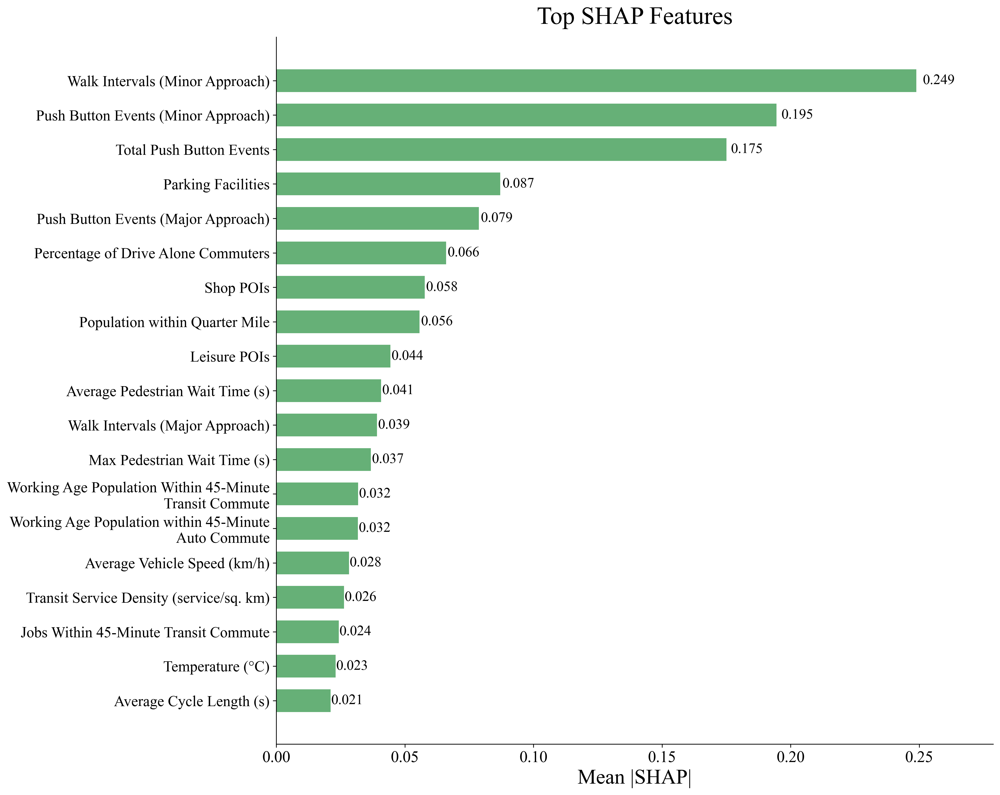

In [3]:
# Fit the citywide model and rank predictors by mean absolute SHAP.
city_model = XGBRegressor(**MODEL_PARAMS).fit(x_np, y.to_numpy())
city_shap_matrix = shap.TreeExplainer(city_model).shap_values(x_np)
feature_importance = pd.Series(np.mean(np.abs(city_shap_matrix), axis=0), index=x_df.columns)
DISPLAY_TOP_N = 19  # Number of features displayed in the importance ranking.
top_features = feature_importance.nlargest(DISPLAY_TOP_N).index.tolist()

# Plot citywide feature importance.
def _wrap_feature_label(label, width=40):
    return '\n'.join(fill(label, width=width).splitlines()) if len(label) > width else label

top_importance = feature_importance.loc[top_features].sort_values(ascending=False)
labels = [_wrap_feature_label(feature) for feature in top_importance.index]
positions = np.arange(len(top_importance))
fig, axis = plt.subplots(figsize=(15, 12), dpi=300)
bars = axis.barh(positions, top_importance.values, height=0.66, alpha=0.9, color='#55A868')
axis.set_yticks(positions)
axis.set_yticklabels(labels, fontsize=16)
axis.set_xlabel('Mean |SHAP|', fontsize=22)
axis.set_title('Top SHAP Features', fontsize=26, pad=14)
axis.invert_yaxis()
axis.set_xlim(0, float(top_importance.max()) * 1.12)
for bar, value in zip(bars, top_importance.values):
    axis.text(bar.get_width() * 1.01, bar.get_y() + bar.get_height() / 2,
              f'{value:.3f}', va='center', ha='left', fontsize=15, clip_on=False)
axis.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## Intersection Context Groups

,Number of clusters (K),Silhouette score,Smallest cluster,Largest cluster
0,2,0.281,98,139
1,3,0.285,9,121
2,4,0.348,9,100
3,5,0.331,7,67
4,6,0.311,7,59
5,7,0.329,5,59
6,8,0.332,1,59
7,9,0.339,1,58
8,10,0.341,1,58


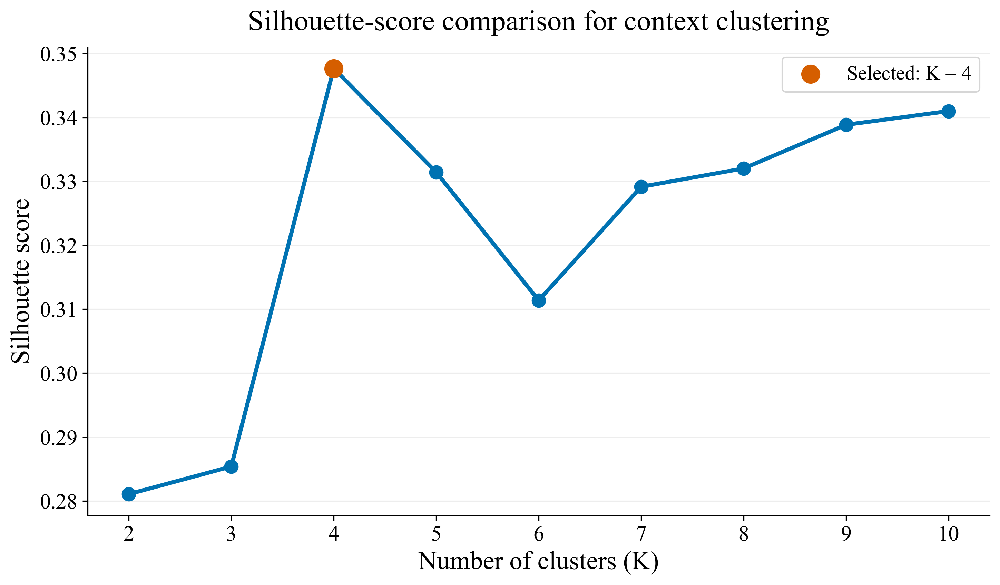

Selected K = 4; silhouette score = 0.348
Intersection cluster sizes: {1: 65, 2: 63, 3: 100, 4: 9}
Hourly-observation cluster sizes: {1: 452, 2: 354, 3: 835, 4: 67}


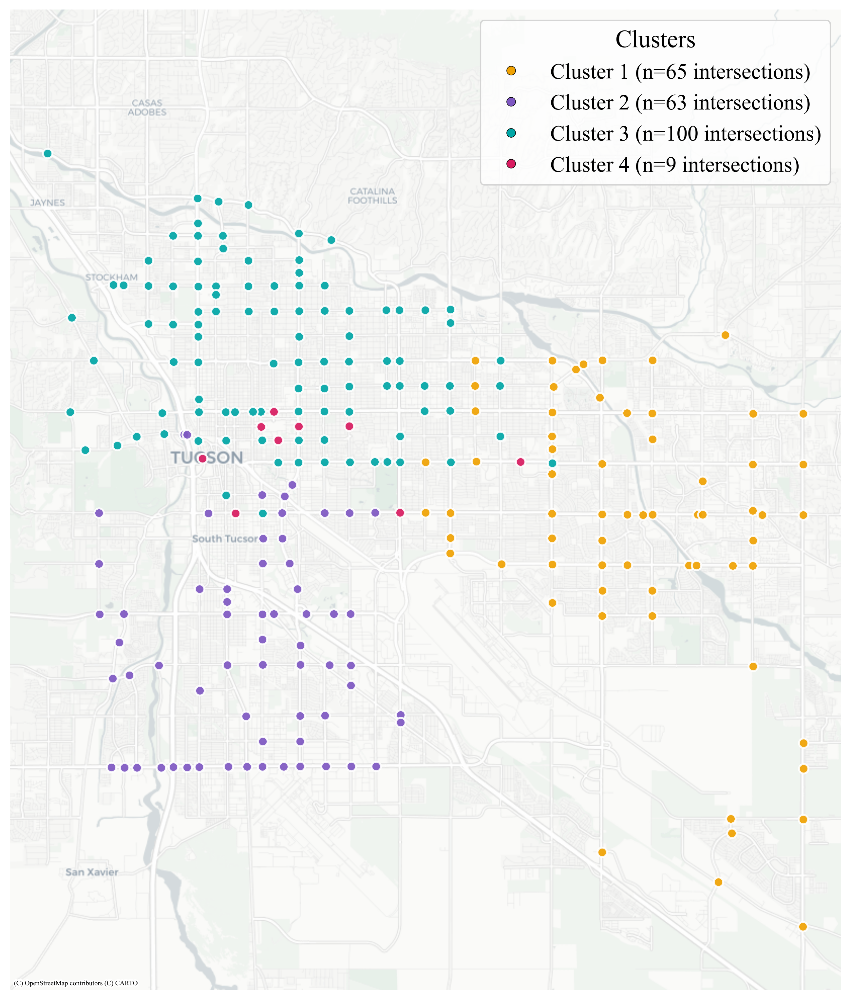

In [43]:
from matplotlib.lines import Line2D
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import geopandas as gpd
import contextily as ctx

# Context typology: projected geography and the selected operational features
# contribute equally as two conceptual blocks. The target is not included.
CONTEXT_K = 4
CONTEXT_RANDOM_STATE = 42
SILHOUETTE_K_VALUES = range(2, 11)
CONTEXT_SIGNAL_FEATURES = [
    'Walk Intervals (Minor Approach)',
    'Push Button Events (Minor Approach)',
    'Total Push Button Events',
]

# Build the context typology at the intersection level. The three predictors
# were selected from the SHAP ranking; their input values are averaged across
# all available hourly observations for each DeviceID before clustering.
intersection_context = raw_df[['DeviceID', 'Latitude', 'Longitude']].copy()
intersection_context[CONTEXT_SIGNAL_FEATURES] = x_df[CONTEXT_SIGNAL_FEATURES].to_numpy(dtype=float)
intersection_context = (
    intersection_context.groupby('DeviceID', as_index=False)
    .agg({
        'Latitude': 'first', 'Longitude': 'first',
        **{feature: 'mean' for feature in CONTEXT_SIGNAL_FEATURES},
    })
)
context_points = gpd.GeoDataFrame(
    intersection_context,
    geometry=gpd.points_from_xy(intersection_context['Longitude'], intersection_context['Latitude']),
    crs='EPSG:4326',
).to_crs(epsg=3857)
projected_xy = np.column_stack([context_points.geometry.x, context_points.geometry.y])

# Standardization makes variables comparable. Dividing each block by the square
# root of its feature count gives geography and signal features equal total weight.
geo_block = StandardScaler().fit_transform(projected_xy) / np.sqrt(2)
signal_block = StandardScaler().fit_transform(
    intersection_context[CONTEXT_SIGNAL_FEATURES].to_numpy(dtype=float)
) / np.sqrt(len(CONTEXT_SIGNAL_FEATURES))
context_matrix = np.hstack([geo_block * np.sqrt(0.50), signal_block * np.sqrt(0.50)])

# Diagnostic comparison for selecting the number of intersection-level clusters.
# The case study uses the specified four-cluster solution.
silhouette_rows = []
for k in SILHOUETTE_K_VALUES:
    labels_k = KMeans(n_clusters=k, random_state=CONTEXT_RANDOM_STATE, n_init=30).fit_predict(context_matrix)
    sizes_k = np.bincount(labels_k)
    silhouette_rows.append({
        'Number of clusters (K)': k,
        'Silhouette score': silhouette_score(context_matrix, labels_k),
        'Smallest cluster': sizes_k.min(),
        'Largest cluster': sizes_k.max(),
    })
silhouette_results = pd.DataFrame(silhouette_rows)
display(silhouette_results.style.format({'Silhouette score': '{:.3f}'}))

fig, axis = plt.subplots(figsize=(10, 6), dpi=300)
axis.plot(silhouette_results['Number of clusters (K)'], silhouette_results['Silhouette score'],
          marker='o', lw=2.8, ms=9, color='#0072B2')
selected_score = silhouette_results.loc[
    silhouette_results['Number of clusters (K)'] == CONTEXT_K, 'Silhouette score'
].iloc[0]
axis.scatter([CONTEXT_K], [selected_score], s=150, color='#D55E00', zorder=3,
             label=f'Selected: K = {CONTEXT_K}')
axis.set_xticks(list(SILHOUETTE_K_VALUES))
axis.set_xlabel('Number of clusters (K)', fontsize=18)
axis.set_ylabel('Silhouette score', fontsize=18)
axis.set_title('Silhouette-score comparison for context clustering', fontsize=20, pad=12)
axis.tick_params(labelsize=15)
axis.grid(axis='y', alpha=0.22)
axis.spines[['top', 'right']].set_visible(False)
axis.legend(fontsize=14, frameon=True)
plt.tight_layout()
plt.show()

intersection_labels = KMeans(
    n_clusters=CONTEXT_K, random_state=CONTEXT_RANDOM_STATE, n_init=30,
).fit_predict(context_matrix)
context_points['Cluster'] = intersection_labels + 1
intersection_group_sizes = pd.Series(intersection_labels + 1).value_counts().sort_index()

# Merge each fixed intersection-level label back to its hourly observations.
# Downstream SHAP plots therefore retain all observations while every DeviceID
# belongs to one and only one cluster.
device_cluster_lookup = context_points.set_index('DeviceID')['Cluster']
context_labels = raw_df['DeviceID'].map(device_cluster_lookup).to_numpy(dtype=int) - 1
context_group_sizes = pd.Series(context_labels + 1).value_counts().sort_index()
print(f'Selected K = {CONTEXT_K}; silhouette score = {selected_score:.3f}')
print('Intersection cluster sizes:', intersection_group_sizes.to_dict())
print('Hourly-observation cluster sizes:', context_group_sizes.to_dict())

# High-contrast, colour-blind-friendly palette used consistently in all figures.
cluster_colors = ['#F0A202', '#7E57C2', '#00A6A6', '#D81B60', '#6D4C41']
context_colors = cluster_colors

# Portrait dimensions and equal aspect retain the actual north--south map geometry.
# Keep the full east--west and southern extent, while removing the northern 30%
# of the map before plotting the cluster points and basemap.
minx, miny, maxx, maxy = context_points.total_bounds
pad_x = (maxx - minx) * 0.05 or 1
pad_y = (maxy - miny) * 0.05 or 1
full_xmin, full_xmax = minx - pad_x, maxx + pad_x
full_ymin, full_ymax = miny - pad_y, maxy + pad_y
cropped_ymax = full_ymax - 0.30 * (full_ymax - full_ymin)
context_points_cropped = context_points[context_points.geometry.y <= cropped_ymax].copy()

fig, axis = plt.subplots(figsize=(9, 14), dpi=300)
legend_handles = []
for cluster_id, color in zip(range(1, CONTEXT_K + 1), cluster_colors):
    subset = context_points_cropped[context_points_cropped['Cluster'] == cluster_id]
    # Visible white outline separates nearby coloured points from the basemap.
    axis.scatter(subset.geometry.x, subset.geometry.y, s=48, c=[color], alpha=0.92,
                 edgecolors='white', linewidths=1.35, zorder=3)
    legend_handles.append(Line2D(
        [0], [0], marker='o', linestyle='', markerfacecolor=color,
        markeredgecolor='black', markeredgewidth=0.4, markersize=np.sqrt(42),
        label=f'Cluster {cluster_id} (n={intersection_group_sizes.loc[cluster_id]} intersections)',
    ))

axis.set_xlim(full_xmin, full_xmax)
axis.set_ylim(full_ymin, cropped_ymax)
try:
    ctx.add_basemap(axis, source=ctx.providers.CartoDB.Positron,
                     crs=context_points.crs.to_string(), attribution_size=5)
except Exception as error:
    print(f'Basemap could not be loaded: {error}')
axis.set_xticks([]); axis.set_yticks([])
axis.set_xlabel(''); axis.set_ylabel('')
axis.set_aspect('equal', adjustable='box')
axis.grid(False)
axis.legend(handles=legend_handles, title='Clusters', frameon=True,
            fontsize=16, title_fontsize=18, loc='upper right')
for spine in axis.spines.values():
    spine.set_visible(False)
plt.tight_layout()
plt.show()

## Citywide and Cluster-Level Feature Importance

Citywide mean absolute SHAP values are compared with the unweighted average of cluster-specific mean absolute SHAP values. Each cluster contributes equally to the cluster-average measure, allowing differences in feature importance across contexts to be examined independently of cluster sample size.

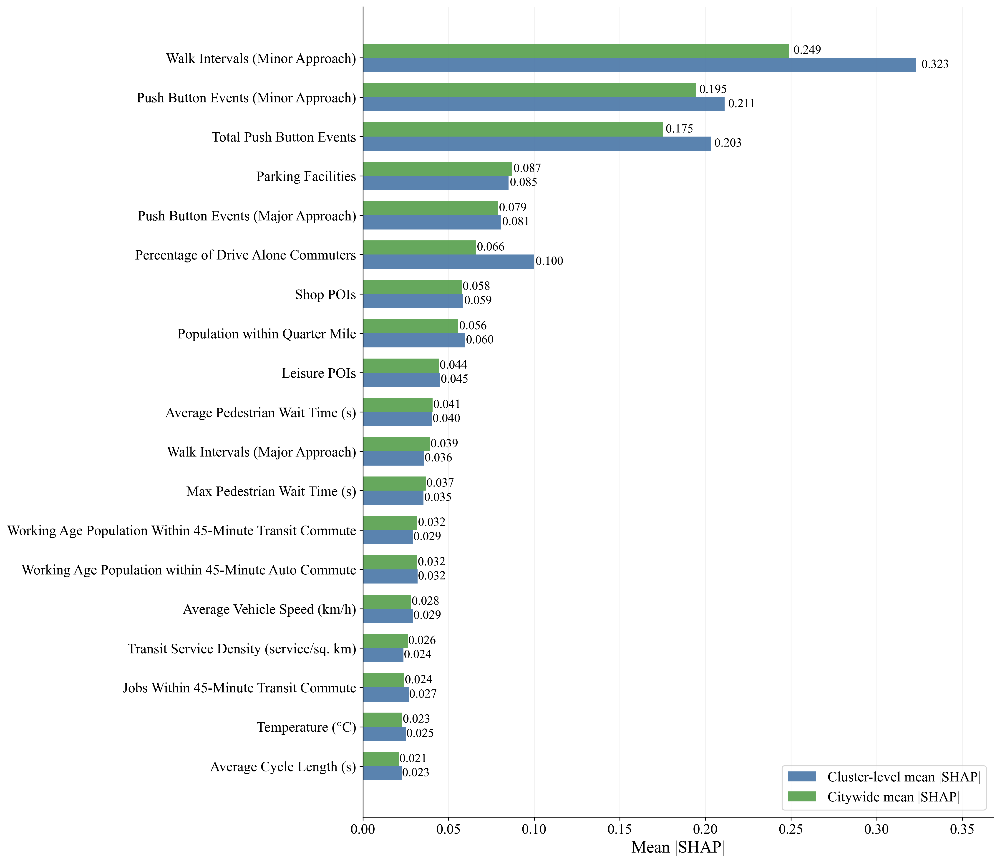

,Citywide mean |SHAP|,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster-level mean |SHAP|
Walk Intervals (Minor Approach),0.248913,0.233177,0.254746,0.228789,0.575057,0.322942
Push Button Events (Minor Approach),0.194520,0.219911,0.239459,0.159158,0.226482,0.211252
Total Push Button Events,0.175088,0.181959,0.169322,0.163999,0.297390,0.203167
Percentage of Drive Alone Commuters,0.065990,0.059426,0.055222,0.061474,0.223445,0.099892
Parking Facilities,0.087089,0.122814,0.129682,0.053986,0.033594,0.085019
Push Button Events (Major Approach),0.078740,0.077292,0.078670,0.078851,0.087499,0.080578
Population within Quarter Mile,0.055706,0.062604,0.076790,0.042990,0.056241,0.059656
Shop POIs,0.057688,0.041865,0.074594,0.058984,0.058963,0.058602
Leisure POIs,0.044321,0.046600,0.048232,0.041450,0.044064,0.045086
Average Pedestrian Wait Time (s),0.040728,0.042056,0.048724,0.037248,0.032886,0.040229


In [38]:
# Compare citywide importance with an equal-weight cluster average.

citywide_mean_abs_shap = pd.Series(
    np.mean(np.abs(city_shap_matrix), axis=0), index=x_df.columns,
)
cluster_mean_abs_shap = pd.DataFrame(
    {
        f'Cluster {cluster_id}': np.mean(
            np.abs(city_shap_matrix[context_labels + 1 == cluster_id]), axis=0,
        )
        for cluster_id in range(1, CONTEXT_K + 1)
    },
    index=x_df.columns,
)
cluster_average_mean_abs_shap = cluster_mean_abs_shap.mean(axis=1)

# Order the comparison by citywide mean absolute SHAP.
IMPORTANCE_TOP_N = 19
importance_ranking = pd.concat(
    [citywide_mean_abs_shap.rename('Citywide'),
     cluster_average_mean_abs_shap.rename('Cluster average')],
    axis=1,
)
importance_display = importance_ranking.nlargest(IMPORTANCE_TOP_N, 'Citywide').sort_values('Citywide')

fig, axis = plt.subplots(figsize=(15, 13), dpi=300)
y_positions = np.arange(len(importance_display))
bar_height = 0.36
cluster_bars = axis.barh(
    y_positions - bar_height / 2, importance_display['Cluster average'],
    height=bar_height, color='#4C78A8', alpha=0.92,
    label='Cluster-level mean |SHAP|',
)
citywide_bars = axis.barh(
    y_positions + bar_height / 2, importance_display['Citywide'],
    height=bar_height, color='#59A14F', alpha=0.92,
    label='Citywide mean |SHAP|',
)

axis.set_yticks(y_positions)
axis.set_yticklabels(importance_display.index, fontsize=15)
axis.set_xlabel('Mean |SHAP|', fontsize=18)

axis.tick_params(axis='x', labelsize=15)
axis.legend(loc='lower right', frameon=True, fontsize=15)
axis.spines[['top', 'right']].set_visible(False)
axis.grid(axis='x', alpha=0.16)
axis.set_axisbelow(True)
axis.set_xlim(0, float(importance_display[['Citywide', 'Cluster average']].to_numpy().max()) * 1.14)

for bar, value in zip(cluster_bars, importance_display['Cluster average']):
    axis.text(bar.get_width() * 1.01, bar.get_y() + bar.get_height() / 2,
              f'{value:.3f}', va='center', ha='left', fontsize=13)
for bar, value in zip(citywide_bars, importance_display['Citywide']):
    axis.text(bar.get_width() * 1.01, bar.get_y() + bar.get_height() / 2,
              f'{value:.3f}', va='center', ha='left', fontsize=13)

plt.tight_layout()
fig.savefig(FIGURE_DIR / "shap_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

# Report feature importance in each cluster to identify contributions to
# differences between the citywide and cluster-average rankings.
cluster_importance_summary = pd.concat(
    [citywide_mean_abs_shap.rename('Citywide mean |SHAP|'), cluster_mean_abs_shap,
     cluster_average_mean_abs_shap.rename('Cluster-level mean |SHAP|')],
    axis=1,
).loc[importance_display.index]
display(cluster_importance_summary.sort_values('Cluster-level mean |SHAP|', ascending=False))

## Citywide and Cluster-Level Response Patterns

In [41]:
import os

from joblib import Parallel, delayed


# Bootstrap citywide dependence values conditional on the fitted model.
# The fitted XGBoost model and its SHAP values remain fixed.

BOOTSTRAP_REPLICATES = 100
BOOTSTRAP_SEED = 20260817
BOOTSTRAP_N_JOBS = os.cpu_count() or 1
CITYWIDE_BOOTSTRAP_MAE_ALLOWANCE_PCT = 10.0
BOOTSTRAP_FEATURES = [
    'Walk Intervals (Minor Approach)',
    'Walk Intervals (Major Approach)',
    'Push Button Events (Minor Approach)',
    'Push Button Events (Major Approach)',
    'Shop POIs',
    'Average Pedestrian Wait Time (s)',
    'Transit Service Density (service/sq. km)',
    'Working Age Population Within 45-Minute Transit Commute',
    'Average Vehicle Speed (km/h)',
    'Temperature (°C)',
]
BOOTSTRAP_CI_LEVEL = 0.95


def _full_candidate_library(x, y):
    """Full-data citywide fits, including every supported segmented size."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    candidates = [_fit_polynomial(x, y, degree) for degree in range(5)]
    candidates.append(_fit_logarithmic(x, y))
    sigmoid = _fit_sigmoid(x, y)
    if sigmoid is not None:
        candidates.append(sigmoid)
    candidates.extend(_fit_segmented_family(x, y, plateau=False))
    candidates.extend(_fit_segmented_family(x, y, plateau=True))
    candidates.extend(_fit_segmented_family(x, y, step=True))
    shap_range = max(float(np.ptp(y)), 1.0)
    for candidate in candidates:
        candidate['nmae_pct'] = 100 * candidate['mae'] / shap_range
        candidate['shap_range'] = shap_range
    return {candidate['method']: candidate for candidate in candidates}


def _one_citywide_bootstrap(seed, values_x, values_shap):
    """Fit the standard candidate workflow once and save all fit information."""
    rng = np.random.default_rng(seed)
    indices = rng.integers(0, values_x.size, size=values_x.size)
    candidates = fit_pattern_library(values_x[indices], values_shap[indices])
    return [
        {
            'Method': candidate['method'],
            'MAE': candidate['mae'],
            'RMSE': candidate['rmse'],
            'R2': candidate['r2'],
            # Saved so each bootstrap curve fit can be inspected later if needed.
            'Coefficients': None if candidate['coefficients'] is None else candidate['coefficients'].copy(),
            'Breakpoints': tuple(candidate['breakpoints']),
            'Equation': candidate['equation'],
        }
        for candidate in candidates
    ]


def _bootstrap_metric_summary(values, level=BOOTSTRAP_CI_LEVEL):
    values = np.asarray(values, dtype=float)
    alpha = (1 - level) / 2
    return {
        'mean': float(np.mean(values)),
        'median': float(np.median(values)),
        'lower': float(np.quantile(values, alpha)),
        'upper': float(np.quantile(values, 1 - alpha)),
        'sd': float(np.std(values, ddof=1)) if values.size > 1 else 0.0,
        'valid_replicates': int(values.size),
    }


# This object is reused by the figure cell. The bootstrap selects the candidate
# types and summarizes their errors; the plotted citywide lines are refitted to
# the complete citywide SHAP data below.
citywide_bootstrap_results = {}
seed_root = np.random.SeedSequence(BOOTSTRAP_SEED)
feature_seed_sequences = seed_root.spawn(len(BOOTSTRAP_FEATURES))

for feature_name, feature_seed_sequence in zip(BOOTSTRAP_FEATURES, feature_seed_sequences):
    feature_position = x_df.columns.get_loc(feature_name)
    values_x = x_np[:, feature_position]
    values_shap = city_shap_matrix[:, feature_position]
    full_city_candidates = _full_candidate_library(values_x, values_shap)
    replicate_seeds = [
        int(child.generate_state(1)[0])
        for child in feature_seed_sequence.spawn(BOOTSTRAP_REPLICATES)
    ]
    replicate_candidates = Parallel(n_jobs=BOOTSTRAP_N_JOBS, prefer='threads')(
        delayed(_one_citywide_bootstrap)(seed, values_x, values_shap)
        for seed in replicate_seeds
    )

    records = [record for result in replicate_candidates for record in result]
    records_frame = pd.DataFrame(records)
    summary_rows = []
    metric_intervals = {}
    for method, method_records in records_frame.groupby('Method', sort=False):
        if method not in full_city_candidates:
            continue
        metrics = {
            'mae': _bootstrap_metric_summary(method_records['MAE']),
            'rmse': _bootstrap_metric_summary(method_records['RMSE']),
            'r2': _bootstrap_metric_summary(method_records['R2']),
        }
        metric_intervals[method] = metrics
        summary_rows.append({
            'Method': method,
            'Mean MAE': metrics['mae']['mean'],
            'Median MAE': metrics['mae']['median'],
            'MAE SD': metrics['mae']['sd'],
            'MAE lower CI': metrics['mae']['lower'],
            'MAE upper CI': metrics['mae']['upper'],
            'Valid replicates': metrics['mae']['valid_replicates'],
        })
    selection_summary = pd.DataFrame(summary_rows).sort_values(
        ['Mean MAE', 'Median MAE', 'Method']
    ).reset_index(drop=True)
    selection_summary = selection_summary.loc[
        selection_summary['Valid replicates'].eq(BOOTSTRAP_REPLICATES)
    ].reset_index(drop=True)
    if selection_summary.empty:
        raise RuntimeError(f'No fully estimable bootstrap candidates for {feature_name}.')

    best_mean_mae = float(selection_summary.iloc[0]['Mean MAE'])
    display_summary = selection_summary.loc[
        selection_summary['Mean MAE'] <= best_mean_mae * (1 + CITYWIDE_BOOTSTRAP_MAE_ALLOWANCE_PCT / 100) + 1e-12
    ].head(MAX_DISPLAY_CANDIDATES).copy()
    display_methods = display_summary['Method'].tolist()

    citywide_bootstrap_results[feature_name] = {
        'city_candidates': [full_city_candidates[method] for method in display_methods],
        'selection_summary': selection_summary.assign(Pattern=lambda frame: frame['Method'].map(_short_method_name)),
        'display_summary': display_summary.assign(Pattern=lambda frame: frame['Method'].map(_short_method_name)),
        'metric_intervals': {method: metric_intervals[method] for method in display_methods},
        'replicate_candidates': replicate_candidates,
        'replicates': BOOTSTRAP_REPLICATES,
    }

bootstrap_citywide_summary = pd.concat([
    result['display_summary'].assign(Feature=feature_name)
    for feature_name, result in citywide_bootstrap_results.items()
], ignore_index=True)
print('One-level bootstrap complete: candidate selection and all metric intervals use the same saved resample fits.')
display(bootstrap_citywide_summary[['Feature', 'Pattern', 'Mean MAE', 'MAE lower CI', 'MAE upper CI', 'Valid replicates']])
print('\nInterpretation note: these intervals describe sampling variability of the citywide SHAP-curve fits conditional on the fixed citywide XGBoost model and its SHAP values.')

One-level bootstrap complete: candidate selection and all metric intervals use the same saved resample fits.


,Feature,Pattern,Mean MAE,MAE lower CI,MAE upper CI,Valid replicates
0,Walk Intervals (Minor Approach),4-segment plateau model,0.043412,0.041030,0.046945,100
1,Walk Intervals (Minor Approach),3-segment piecewise-linear,0.043939,0.041492,0.046578,100
2,Walk Intervals (Major Approach),Sigmoid,0.018049,0.017223,0.019082,100
3,Push Button Events (Minor Approach),Sigmoid,0.054222,0.051346,0.057076,100
4,Push Button Events (Major Approach),Quartic,0.031212,0.029611,0.032852,100
5,Push Button Events (Major Approach),Sigmoid,0.031643,0.027926,0.035161,100
6,Push Button Events (Major Approach),Cubic,0.033514,0.031541,0.036163,100
7,Shop POIs,Sigmoid,0.021569,0.020337,0.022990,100
8,Shop POIs,2-segment plateau model,0.022379,0.020956,0.023942,100
9,Shop POIs,2-segment piecewise-linear,0.022489,0.020938,0.024130,100



Interpretation note: these intervals describe sampling variability of the citywide SHAP-curve fits conditional on the fixed citywide XGBoost model and its SHAP values.


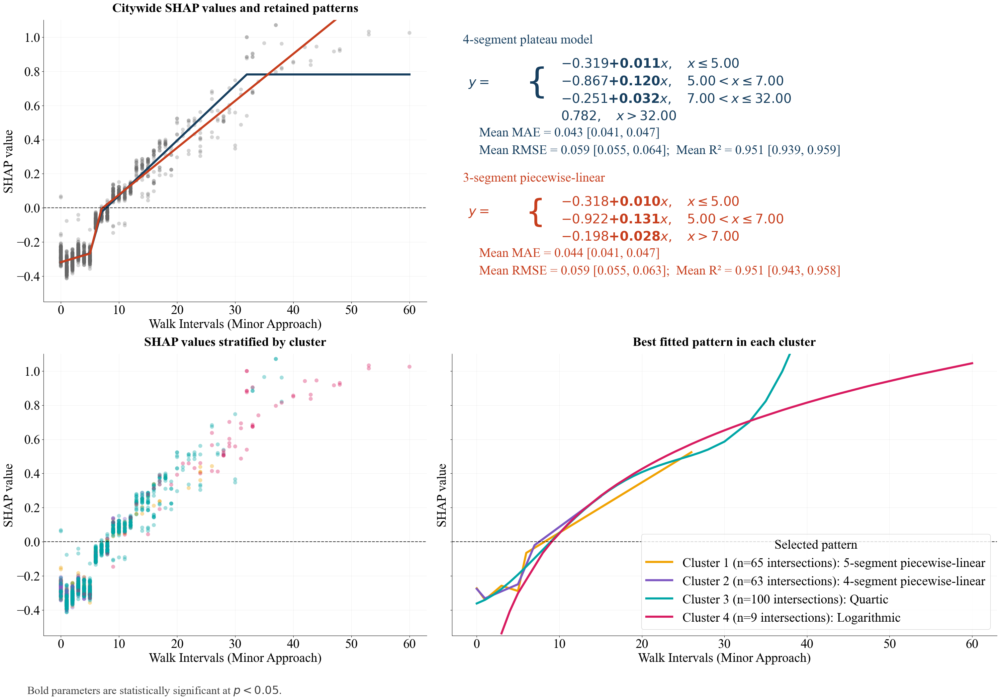

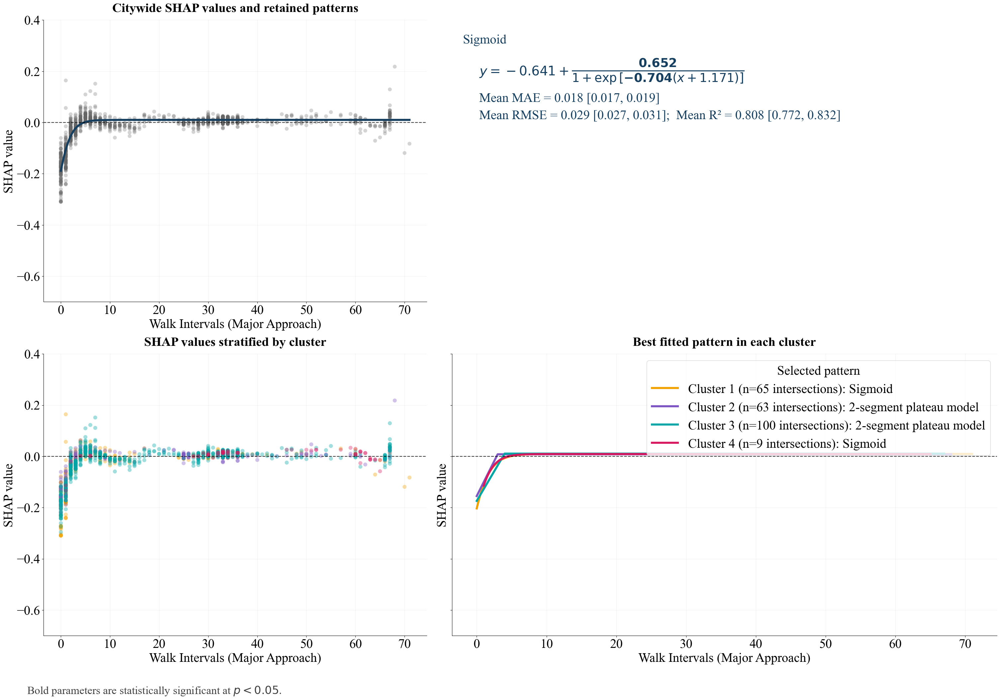

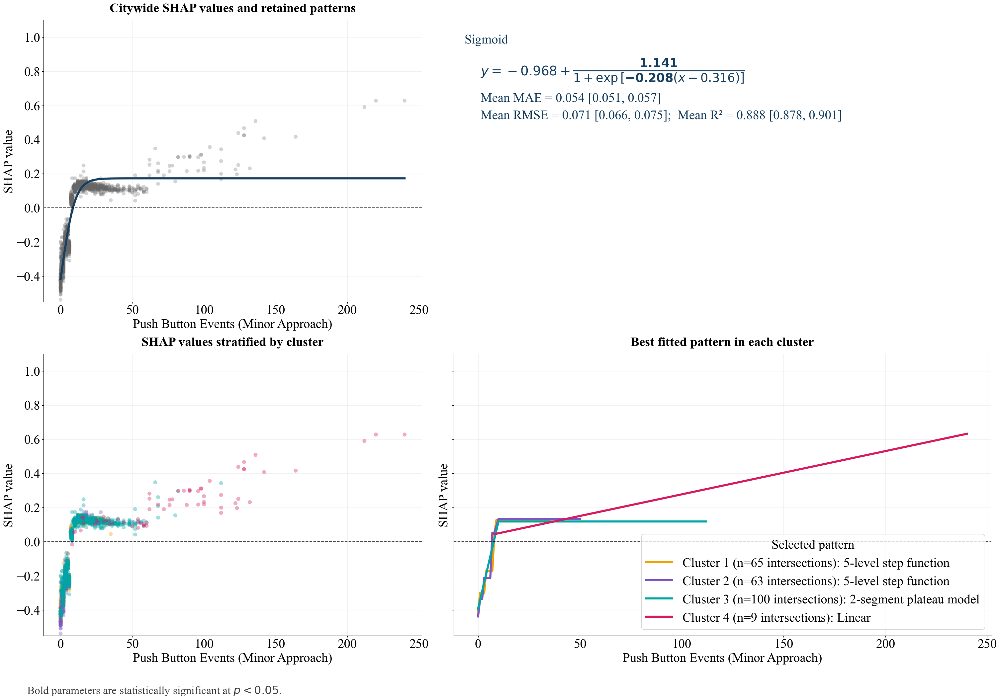

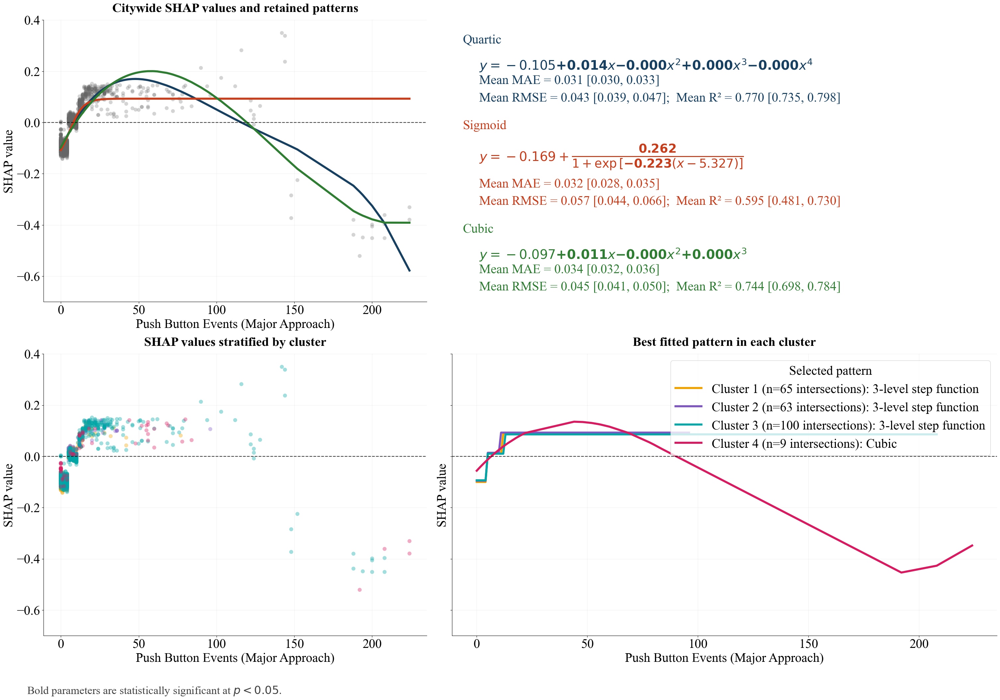

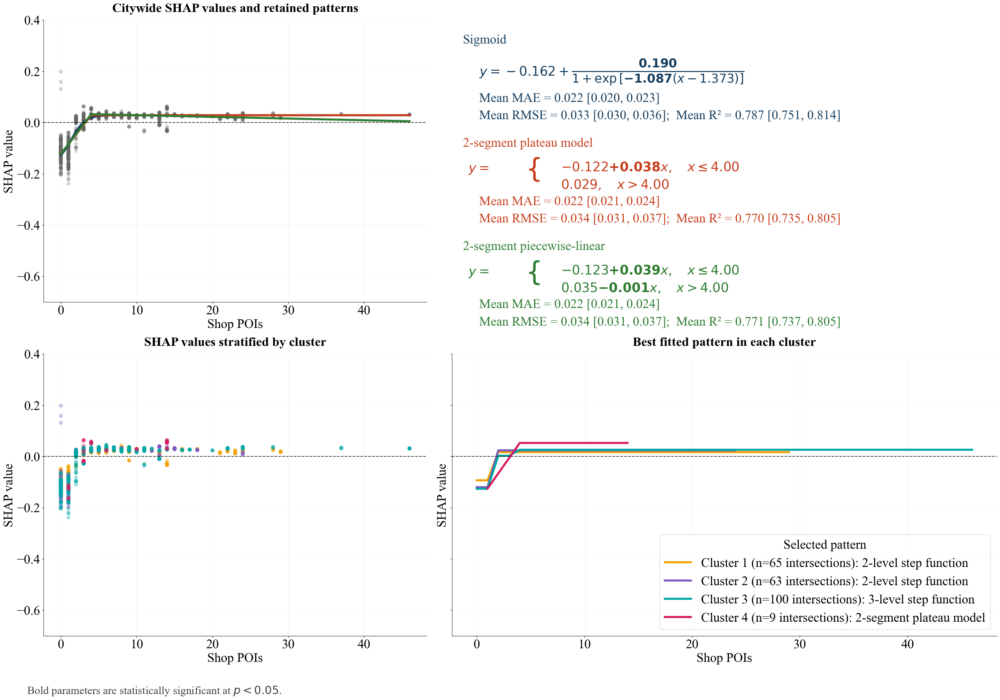

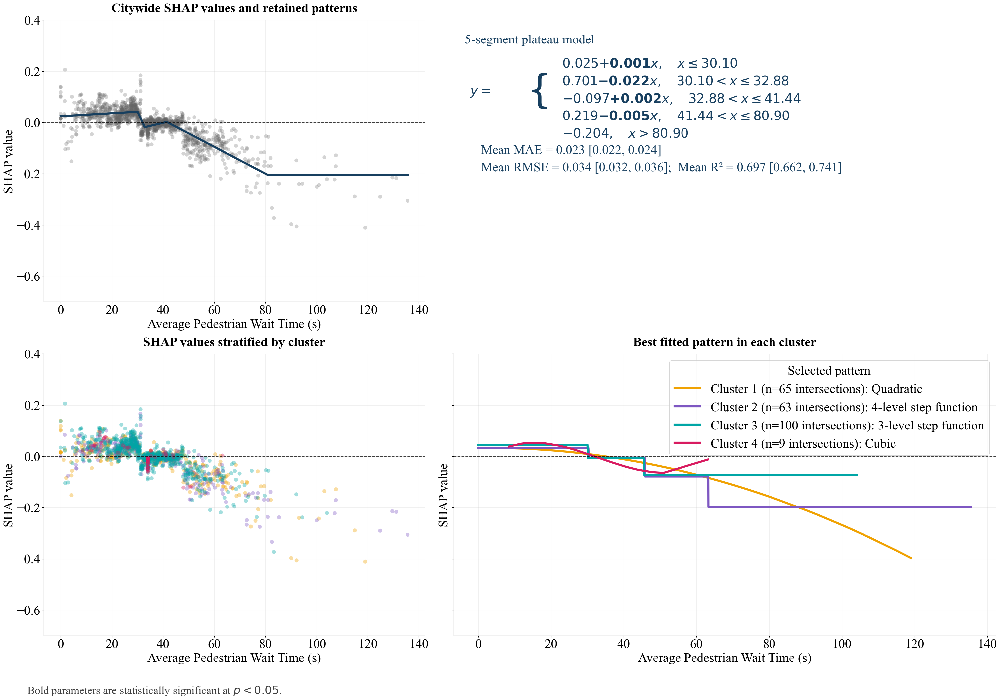

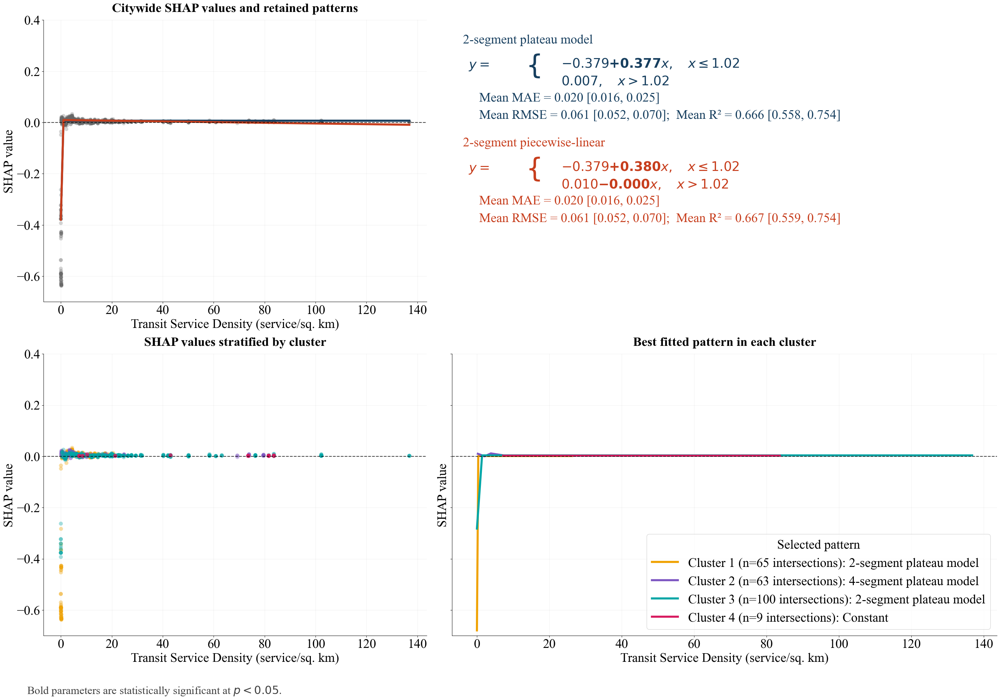

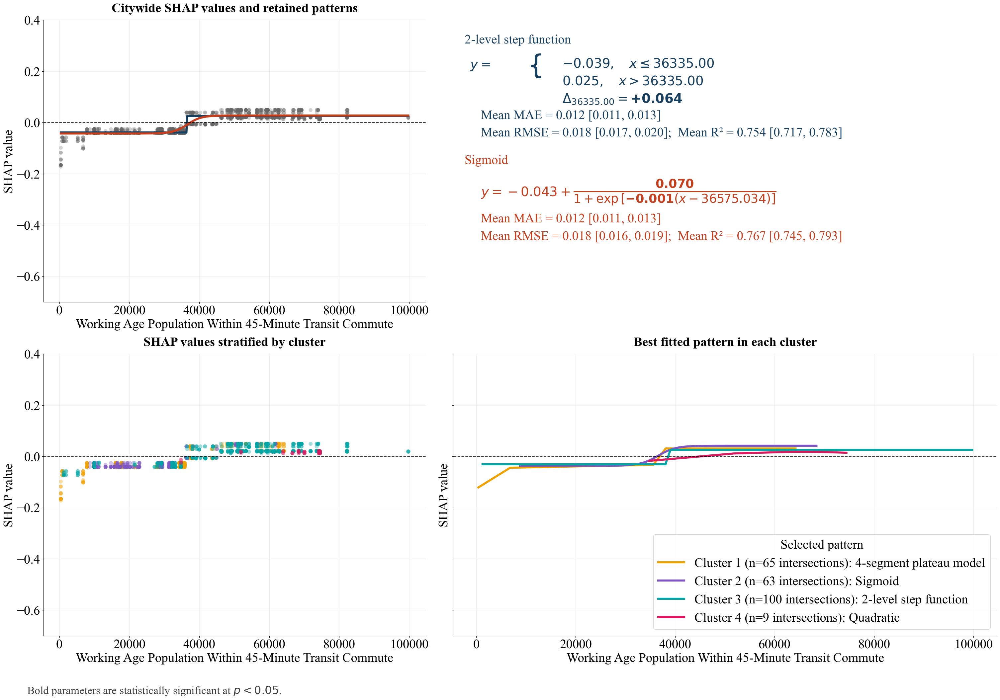

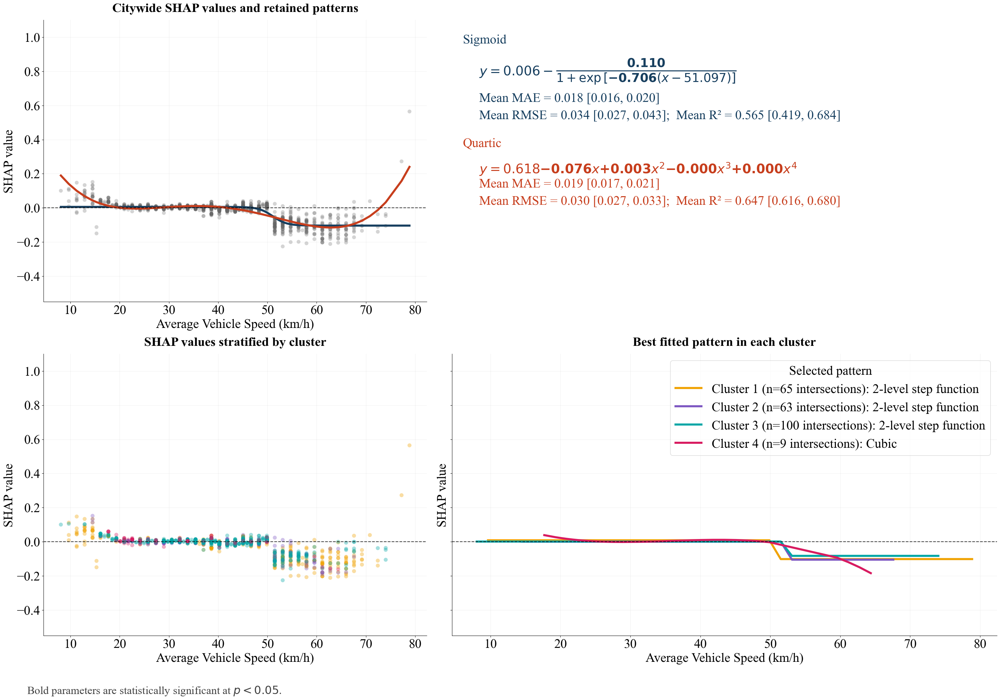

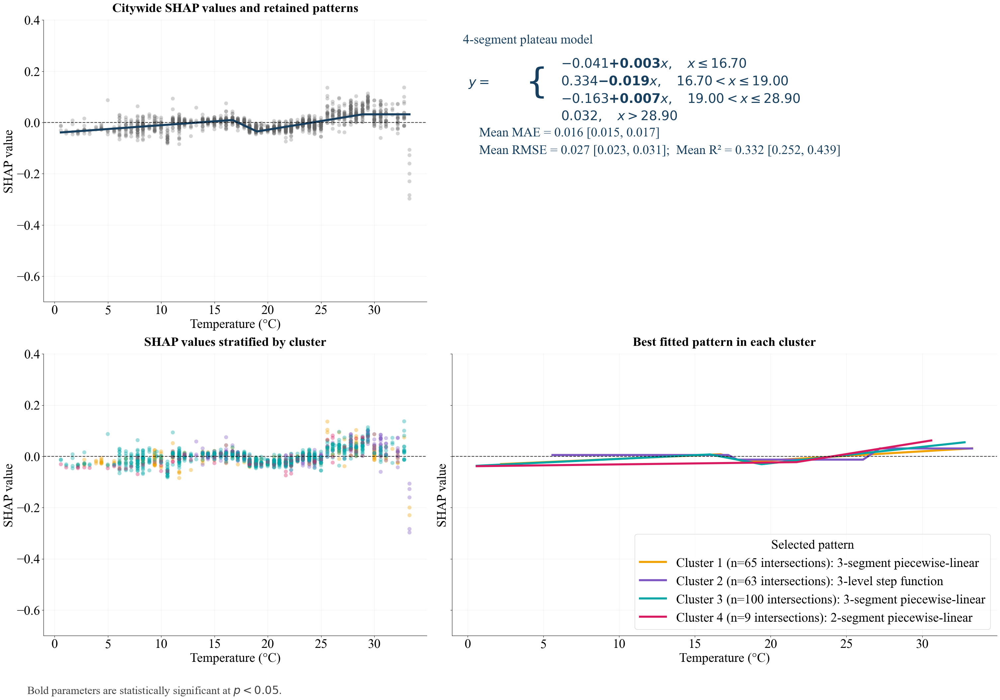

,Feature,Cluster,N,Selected pattern,Equation,MAE,RMSE,R2,NMAE (%)
0,Walk Intervals (Minor Approach),1,452,Continuous piecewise (5 segments),$y = -0.273-0.067x + \sum_j \Delta_j(x-\tau_j)...,0.026573,0.033522,9.615808e-01,3.157307
1,Walk Intervals (Minor Approach),2,354,Continuous piecewise (4 segments),$y = -0.276-0.056x + \sum_j \Delta_j(x-\tau_j)...,0.033576,0.039371,9.130082e-01,4.846532
2,Walk Intervals (Minor Approach),3,835,Quartic,$y = -0.362 +0.017x +0.005x^{2} -0.000x^{3} +0...,0.049955,0.068930,9.305565e-01,3.367404
3,Walk Intervals (Minor Approach),4,67,Logarithmic,$y = -1.342 +0.581\ln(1+x)$,0.077587,0.108266,9.048217e-01,5.688897
4,Walk Intervals (Major Approach),1,452,Sigmoid,"$y = -0.895+0.905\,\sigma\!\left(0.704(x--1.67...",0.024076,0.038027,7.674028e-01,5.081123
5,Walk Intervals (Major Approach),2,354,Continuous plateau (2 segments),$\mathrm{Connected\ plateau};\quad \tau = (3.0...,0.016350,0.025274,8.267808e-01,3.731676
6,Walk Intervals (Major Approach),3,835,Continuous plateau (2 segments),$\mathrm{Connected\ plateau};\quad \tau = (4.0...,0.015534,0.024176,8.292192e-01,3.473857
7,Walk Intervals (Major Approach),4,67,Sigmoid,"$y = -0.802+0.811\,\sigma\!\left(0.781(x--1.19...",0.010700,0.014935,6.911106e-01,6.407236
8,Push Button Events (Minor Approach),1,452,Piecewise-constant step (5 ranges),$y = c_j\quad \mathrm{within\ level}\ j;\quad ...,0.036268,0.057621,9.183738e-01,5.659933
9,Push Button Events (Minor Approach),2,354,Piecewise-constant step (5 ranges),$y = c_j\quad \mathrm{within\ level}\ j;\quad ...,0.027881,0.037988,9.685816e-01,3.914777



Conditional citywide coefficient/contrast tests (selected form and breakpoints treated as fixed)


,Feature,Pattern,Parameter / contrast,Estimate,Standard error,t-value,p-value
0,Walk Intervals (Minor Approach),4-segment plateau model,Segment 1 slope,0.0107,0.0011,9.384,1.96e-20
1,Walk Intervals (Minor Approach),4-segment plateau model,Segment 2 slope,0.0107,0.0011,9.384,1.96e-20
2,Walk Intervals (Minor Approach),4-segment plateau model,Segment 3 slope,0.1204,0.0025,49.112,0
3,Walk Intervals (Minor Approach),4-segment plateau model,Slope change at x = 7.00,0.1097,0.0033,33.126,3.54e-186
4,Walk Intervals (Minor Approach),4-segment plateau model,Slope change at x = 32.00,-0.1204,0.0025,-49.112,0
5,Walk Intervals (Minor Approach),3-segment piecewise-linear,Segment 1 slope,0.0101,0.0011,8.880,1.66e-18
6,Walk Intervals (Minor Approach),3-segment piecewise-linear,Segment 2 slope,0.0101,0.0011,8.880,1.66e-18
7,Walk Intervals (Minor Approach),3-segment piecewise-linear,Segment 3 slope,0.1310,0.0024,54.231,0
8,Walk Intervals (Minor Approach),3-segment piecewise-linear,Slope change at x = 7.00,0.1209,0.0033,36.732,4.59e-218
9,Walk Intervals (Major Approach),Sigmoid,Amplitude,0.6516,0.2446,2.664,0.0078


In [45]:
# Citywide SHAP values are stratified by cluster. No local models are trained here.

from matplotlib.offsetbox import AnchoredOffsetbox, HPacker, TextArea
# Format equations and parameter diagnostics for the comparison figures.
def _visual_test_pvalues(candidate):
    tests = conditional_parameter_tests(candidate)
    allowed = None
    if candidate['method'] == 'Sigmoid':
        allowed = {'Amplitude', 'Steepness'}
    elif candidate['method'].startswith('Continuous piecewise') or candidate['method'].startswith('Continuous plateau'):
        allowed = {test['Parameter / contrast'] for test in tests
                   if test['Parameter / contrast'].startswith('Segment ')}
    return {test['Parameter / contrast']: test['p-value'] for test in tests
            if allowed is None or test['Parameter / contrast'] in allowed}


def _visual_latex_number(value, signed=False, p_value=np.nan):
    text = f'{value:+.3f}' if signed else f'{value:.3f}'
    if p_value < 0.05:
        return rf'\mathbf{{{text}}}'
    return text


def _visual_display_equation(candidate):
    coefficients = candidate.get('coefficients')
    if coefficients is None:
        return candidate['equation']
    test_pvalues = _visual_test_pvalues(candidate)
    method = candidate['method']
    if method == 'Linear':
        slope = _visual_latex_number(coefficients[1], signed=True, p_value=test_pvalues.get('Slope (x)', np.nan))
        return rf'$y = {coefficients[0]:.3f}{slope}x$'
    if method == 'Logarithmic':
        coefficient = _visual_latex_number(coefficients[1], signed=True, p_value=test_pvalues.get('Log coefficient', np.nan))
        return rf'$y = {coefficients[0]:.3f} {coefficient}\ln(1+x)$'
    if method in {'Quadratic', 'Cubic', 'Quartic'}:
        terms = [f'{coefficients[0]:.3f}']
        for power, coefficient in enumerate(coefficients[1:], start=1):
            label = f'Coefficient of x^{power}'
            term = _visual_latex_number(coefficient, signed=True, p_value=test_pvalues.get(label, np.nan))
            terms.append(rf'{term}x' if power == 1 else rf'{term}x^{{{power}}}')
        return r'$y = ' + ' '.join(terms) + r'$'
    if method == 'Sigmoid':
        amplitude_sign = '+' if coefficients[1] >= 0 else '-'
        amplitude = _visual_latex_number(abs(coefficients[1]),
                                         p_value=test_pvalues.get('Amplitude', np.nan))
        exponent = _visual_latex_number(-coefficients[2], signed=True,
                                       p_value=test_pvalues.get('Steepness', np.nan))
        midpoint_term = f'x{-coefficients[3]:+.3f}'
        return (rf'$y = {coefficients[0]:.3f} {amplitude_sign} '
                rf'\frac{{{amplitude}}}{{1 + \exp\left[{exponent}({midpoint_term})\right]}}$')
    return candidate['equation']


def _visual_sigmoid_equation_parts(candidate):
    """Return separately sized prefix and logistic fraction for display."""
    coefficients = candidate['coefficients']
    test_pvalues = _visual_test_pvalues(candidate)
    amplitude_sign = '+' if coefficients[1] >= 0 else '-'
    amplitude = _visual_latex_number(abs(coefficients[1]),
                                     p_value=test_pvalues.get('Amplitude', np.nan))
    exponent = _visual_latex_number(-coefficients[2], signed=True,
                                   p_value=test_pvalues.get('Steepness', np.nan))
    midpoint_term = f'x{-coefficients[3]:+.3f}'
    prefix = rf'$y = {coefficients[0]:.3f} {amplitude_sign}$'
    fraction = rf'$\frac{{{amplitude}}}{{1 + \exp\left[{exponent}({midpoint_term})\right]}}$'
    return prefix, fraction


def _visual_piecewise_rows(candidate, x_min, x_max):
    breakpoints = tuple(candidate['breakpoints'])
    if not breakpoints:
        return None
    coefficients = candidate['coefficients']
    if candidate['method'].startswith('Piecewise-constant step'):
        return [(f'{level:.3f}', _range_label(index, breakpoints).removeprefix('$').removesuffix('$'))
                for index, level in enumerate(coefficients)]
    plateau = candidate['method'].startswith('Continuous plateau')
    test_pvalues = _visual_test_pvalues(candidate)
    edges = (x_min, *breakpoints, x_max)
    rows = []
    for index, (left, right) in enumerate(zip(edges[:-1], edges[1:])):
        y_left = _continuous_piecewise_value(left, coefficients, breakpoints, plateau)
        y_right = _continuous_piecewise_value(right, coefficients, breakpoints, plateau)
        slope = (y_right - y_left) / (right - left)
        intercept = y_left - slope * left
        slope_text = _visual_latex_number(slope, signed=True,
                                           p_value=test_pvalues.get(f'Segment {index + 1} slope', np.nan))
        formula = f'{intercept:.3f}' if abs(slope) < 5e-8 else f'{intercept:.3f}{slope_text}x'
        condition = _range_label(index, breakpoints).removeprefix('$').removesuffix('$')
        rows.append((formula, condition))
    return rows


def _visual_step_jump_lines(candidate):
    jump_pvalues = {result['Parameter / contrast']: result['p-value']
                    for result in conditional_parameter_tests(candidate)
                    if result['Parameter / contrast'].startswith('Level jump')}
    lines = []
    for index, breakpoint in enumerate(candidate['breakpoints']):
        jump = candidate['coefficients'][index + 1] - candidate['coefficients'][index]
        label = f'Level jump at x = {breakpoint:.2f}'
        jump_text = _visual_latex_number(jump, signed=True, p_value=jump_pvalues.get(label, np.nan))
        lines.append(rf'$\Delta_{{{breakpoint:.2f}}} = {jump_text}$')
    return lines

candidate_colors = ['#173F5F', '#C73E1D', '#2E7D32']
BOTTOM_RIGHT_CLUSTER_LEGEND_FEATURES = {
    'Temperature (°C)',
    'Working Age Population Within 45-Minute Transit Commute',
    'Transit Service Density (service/sq. km)',
    'Shop POIs',
    'Push Button Events (Minor Approach)',
    'Walk Intervals (Minor Approach)',
}
if 'citywide_bootstrap_results' not in globals():
    raise RuntimeError('Run the citywide bootstrap cell before generating these figures.')

features_to_plot = list(BOOTSTRAP_FEATURES)
context_pattern_results = {feature_name: [] for feature_name in features_to_plot}
for feature_name in features_to_plot:
    position = x_df.columns.get_loc(feature_name)
    for group_id in range(1, CONTEXT_K + 1):
        mask = context_labels + 1 == group_id
        values_x = x_np[mask, position]
        values_shap = city_shap_matrix[mask, position]
        candidates = fit_pattern_library(values_x, values_shap)
        context_pattern_results[feature_name].append({
            'group': group_id, 'n_observations': int(mask.sum()),
            'n_intersections': int(intersection_group_sizes.loc[group_id]),
            'x': values_x, 'shap': values_shap,
            'selected': retained_candidates(candidates)[0],
        })

EXAMPLE_PATTERN_FIGURES = {
    'Average Pedestrian Wait Time (s)': 'pedestrian_wait_time_patterns.png',
    'Average Vehicle Speed (km/h)': 'vehicle_speed_patterns.png',
}

# Display citywide and cluster fits for each selected determinant.

for feature_name in features_to_plot:
    position = x_df.columns.get_loc(feature_name)
    values_x = x_np[:, position]
    values_shap = city_shap_matrix[:, position]
    bootstrap_result = citywide_bootstrap_results[feature_name]
    metric_intervals = bootstrap_result['metric_intervals']
    shown_city_candidates = sorted(
        bootstrap_result['city_candidates'],
        key=lambda candidate: metric_intervals[candidate['method']]['mae']['mean'],
    )
    group_results = context_pattern_results[feature_name]
    high_range_features = {
        'Walk Intervals (Minor Approach)',
        'Push Button Events (Minor Approach)',
        'Average Vehicle Speed (km/h)',
    }
    y_limits = (-0.55, 1.10) if feature_name in high_range_features else (-0.70, 0.40)

    fig, axes = plt.subplots(2, 2, figsize=(30, 20), sharey='row',
                             gridspec_kw={'width_ratios': [0.95, 1.35]},
                             constrained_layout=True)
    FIGURE_FONT_SIZE = 28
    city_axis, statistics_axis = axes[0]
    group_points_axis, group_fit_axis = axes[1]
    order = np.argsort(values_x)
    city_axis.scatter(values_x, values_shap, s=70, alpha=0.28, color='0.40', edgecolors='none')
    for color, candidate in zip(candidate_colors, shown_city_candidates):
        if candidate['method'] == 'Sigmoid':
            curve_x = np.linspace(np.min(values_x), np.max(values_x), 400)
            curve_y = _sigmoid_function(curve_x, *candidate['coefficients'])
            city_axis.plot(curve_x, curve_y, lw=4.5, color=color)
        else:
            city_axis.plot(values_x[order], candidate['fitted'][order], lw=4.5, color=color)
    city_axis.set_title('Citywide SHAP values and retained patterns', fontsize=FIGURE_FONT_SIZE,
                        pad=18, fontweight='bold')

    statistics_axis.axis('off')
    text_y = 0.95
    for color, candidate in zip(candidate_colors, shown_city_candidates):
        rows = _visual_piecewise_rows(candidate, np.min(values_x), np.max(values_x))
        statistics_axis.text(0.02, text_y, _short_method_name(candidate['method']),
                             transform=statistics_axis.transAxes, va='top', ha='left',
                             fontsize=FIGURE_FONT_SIZE, color=color)
        line_y = text_y - 0.082
        if rows:
            row_step = 0.062
            brace_center = line_y - row_step * (len(rows) - 1) / 2
            brace_size = FIGURE_FONT_SIZE * (1.45 + 0.32 * len(rows))
            statistics_axis.text(0.03, brace_center, r'$y =$ ', transform=statistics_axis.transAxes,
                                 va='center', ha='left', fontsize=FIGURE_FONT_SIZE, color=color)
            statistics_axis.text(0.135, brace_center, r'$\{$', transform=statistics_axis.transAxes,
                                 va='center', ha='left', fontsize=brace_size, color=color)
            for row_index, (formula, condition) in enumerate(rows, start=1):
                statistics_axis.text(0.20, line_y,
                                     rf'${formula},\quad {condition.removeprefix("$").removesuffix("$")}$',
                                     transform=statistics_axis.transAxes, va='top', ha='left',
                                     fontsize=FIGURE_FONT_SIZE, color=color)
                line_y -= row_step
            if candidate['method'].startswith('Piecewise-constant step'):
                for jump_line in _visual_step_jump_lines(candidate):
                    statistics_axis.text(0.20, line_y, jump_line,
                                         transform=statistics_axis.transAxes, va='top', ha='left',
                                         fontsize=FIGURE_FONT_SIZE, color=color)
                    line_y -= row_step
        else:
            if candidate['method'] == 'Sigmoid':
                sigmoid_prefix, sigmoid_fraction = _visual_sigmoid_equation_parts(candidate)
                equation_box = HPacker(
                    children=[
                        TextArea(sigmoid_prefix, textprops={'fontsize': FIGURE_FONT_SIZE, 'color': color}),
                        TextArea(sigmoid_fraction, textprops={'fontsize': FIGURE_FONT_SIZE * 1.35, 'color': color}),
                    ],
                    align='center', pad=0, sep=7,
                )
                statistics_axis.add_artist(AnchoredOffsetbox(
                    loc='upper left', child=equation_box, frameon=False, pad=0, borderpad=0,
                    bbox_to_anchor=(0.05, line_y), bbox_transform=statistics_axis.transAxes,
                ))
                line_y -= 0.125
            else:
                statistics_axis.text(0.05, line_y, _visual_display_equation(candidate),
                                     transform=statistics_axis.transAxes, va='top', ha='left',
                                     fontsize=FIGURE_FONT_SIZE, color=color)
                line_y -= 0.062
        intervals = metric_intervals.get(candidate['method'])
        if intervals is None:
            metric_text = (f'Citywide MAE = {candidate["mae"]:.3f};  '
                           f'RMSE = {candidate["rmse"]:.3f};  R² = {candidate["r2"]:.3f}')
            interval_text = 'Bootstrap interval unavailable'
        else:
            metric_text = (f'Mean MAE = {intervals["mae"]["mean"]:.3f} '
                           f'[{intervals["mae"]["lower"]:.3f}, {intervals["mae"]["upper"]:.3f}]')
            interval_text = (f'Mean RMSE = {intervals["rmse"]["mean"]:.3f} '
                             f'[{intervals["rmse"]["lower"]:.3f}, {intervals["rmse"]["upper"]:.3f}];  '
                             f'Mean R² = {intervals["r2"]["mean"]:.3f} '
                             f'[{intervals["r2"]["lower"]:.3f}, {intervals["r2"]["upper"]:.3f}]')
        statistics_axis.text(0.05, line_y, metric_text,
                             transform=statistics_axis.transAxes, va='top', ha='left',
                             fontsize=FIGURE_FONT_SIZE, color=color)
        statistics_axis.text(0.05, line_y - 0.062, interval_text,
                             transform=statistics_axis.transAxes, va='top', ha='left',
                             fontsize=FIGURE_FONT_SIZE, color=color)
        text_y = line_y - 0.16

    for result, color in zip(group_results, context_colors):
        group_points_axis.scatter(result['x'], result['shap'], s=75, alpha=0.36,
                                  color=color, edgecolors='none')
        group_order = np.argsort(result['x'])
        selected = result['selected']
        if selected['method'] == 'Sigmoid':
            curve_x = np.linspace(np.min(result['x']), np.max(result['x']), 400)
            curve_y = _sigmoid_function(curve_x, *selected['coefficients'])
            group_fit_axis.plot(curve_x, curve_y, lw=4.5, color=color,
                                label=f"Cluster {result['group']} (n={result['n_intersections']} intersections): {_short_method_name(selected['method'])}")
        else:
            group_fit_axis.plot(result['x'][group_order], selected['fitted'][group_order], lw=4.5,
                                color=color,
                                label=f"Cluster {result['group']} (n={result['n_intersections']} intersections): {_short_method_name(selected['method'])}")
    for axis in (city_axis, group_points_axis, group_fit_axis):
        axis.axhline(0, color='black', lw=1.6, ls='--', alpha=0.75)
        axis.set_ylim(y_limits)
        axis.set_xlabel(feature_name, fontsize=FIGURE_FONT_SIZE)
        axis.set_ylabel('SHAP value', fontsize=FIGURE_FONT_SIZE)
        axis.tick_params(labelsize=FIGURE_FONT_SIZE)
        axis.grid(alpha=0.18)
        axis.spines[['top', 'right']].set_visible(False)
    group_points_axis.set_title('SHAP values stratified by cluster', fontsize=FIGURE_FONT_SIZE,
                                pad=18, fontweight='bold')
    group_fit_axis.set_title('Best fitted pattern in each cluster', fontsize=FIGURE_FONT_SIZE,
                             pad=18, fontweight='bold')
    legend_location = 'lower right' if feature_name in BOTTOM_RIGHT_CLUSTER_LEGEND_FEATURES else 'upper right'
    group_fit_axis.legend(loc=legend_location, frameon=True, fontsize=FIGURE_FONT_SIZE,
                          title='Selected pattern', title_fontsize=FIGURE_FONT_SIZE)
    # Reserve a narrow lower margin for the significance note.
    fig.get_layout_engine().set(rect=(0, 0.065, 1, 1))
    fig.text(0.025, 0.018,
             r'Bold parameters are statistically significant at $p < 0.05$.',
             ha='left', va='bottom', fontsize=FIGURE_FONT_SIZE * 0.86, color='0.25')
    if feature_name in EXAMPLE_PATTERN_FIGURES:
        filename = EXAMPLE_PATTERN_FIGURES[feature_name]
        fig.savefig(FIGURE_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()

context_pattern_summary = pd.DataFrame([
    {'Feature': feature, 'Cluster': result['group'], 'N': result['n_observations'],
     'Selected pattern': result['selected']['method'], 'Equation': result['selected']['equation'],
     'MAE': result['selected']['mae'], 'RMSE': result['selected']['rmse'],
     'R2': result['selected']['r2'], 'NMAE (%)': result['selected']['nmae_pct']}
    for feature, results in context_pattern_results.items() for result in results
])
display(context_pattern_summary)

# Conditional citywide coefficient/contrast diagnostics for displayed fits.
citywide_conditional_test_rows = []
for feature_name in features_to_plot:
    for candidate in citywide_bootstrap_results[feature_name]['city_candidates']:
        for result in conditional_parameter_tests(candidate):
            citywide_conditional_test_rows.append({'Feature': feature_name,
                                                   'Pattern': _short_method_name(candidate['method']),
                                                   **result})
citywide_conditional_test_summary = pd.DataFrame(citywide_conditional_test_rows)
if not citywide_conditional_test_summary.empty:
    print('\nConditional citywide coefficient/contrast tests (selected form and breakpoints treated as fixed)')
    display(citywide_conditional_test_summary.style.format({
        'Estimate': '{:.4f}', 'Standard error': '{:.4f}',
        't-value': '{:.3f}', 'p-value': '{:.3g}',
    }))